# Exploring Behavioral Factors at NovaRetail+

NovaRetail+ is an e-commerce platform in Latin America with millions of users. For the close of 2024, the **Growth and Retention** team wants to answer:

**Which customer behavior factors are most strongly associated with annual revenue generated?**

> This project is a **correlational** (exploratory) analysis. **Correlation ≠ causation.**

## Section 1. Load and explore the dataset

This section validates that the dataset loads correctly, reviews the data types, and explores missing values and general ranges.

In [1]:
# Import libraries
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt


### Load the dataset

The file `novaretail_comportamiento_clientes_2024.csv` is loaded into the DataFrame `df`, and its structure is reviewed with `.info()`.

In [2]:
# Load the dataset and explore the data
df = pd.read_csv('/datasets/novaretail_comportamiento_clientes_2024.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Dataset description

The dataset contains the following columns:

- `id_cliente`: unique customer identifier.
- `edad`: customer age.
- `nivel_ingreso`: estimated annual income of the customer.
- `visitas_mes`: number of visits to the app or website during the month.
- `compras_mes`: number of purchases made during the month.
- `gasto_publicidad_dirigida`: ad spend assigned to the user.
- `satisfaccion`: customer satisfaction rating on a scale of 1 to 5.
- `miembro_premium`: indicates whether the customer has a premium subscription (1) or not (0).
- `abandono`: indicates whether the customer left the platform (1) or not (0).
- `tipo_dispositivo`: type of device used by the customer (mobile, desktop or tablet).
- `region`: customer's geographic region (north, south, west or east).
- `ingreso_anual`: annual revenue generated by the customer for the company.

The main metric of the analysis is `ingreso_anual`, used to assess the economic impact of customers.

The first 5 rows of the dataset are displayed.

In [3]:
# Show the first 5 rows
df.head()

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Section 2. Prepare the data and document assumptions

### Exploration and cleaning

#### Initial data exploration

The dataset contains **15,000 records** and **12 columns**, with no null values.

**Numeric variables:** `edad`, `nivel_ingreso`, `visitas_mes`, `compras_mes`, `gasto_publicidad_dirigida`, `satisfaccion` and `ingreso_anual`. All of them have appropriate data types.

**Binary variables:** `miembro_premium` and `abandono`. They are stored as integers (0/1), but since they are binary variables they should be converted to boolean.

**Categorical variables:** `id_cliente`, `tipo_dispositivo` and `region`. They are correctly defined and need no further transformation.

#### Fix the data type

The binary columns are converted to boolean with `.astype('bool')`, and the change is verified with `.info()`.

In [4]:
# Fix the data type
df['miembro_premium'] = df['miembro_premium'].astype ('bool')
df['abandono'] = df['abandono'].astype ('bool')

In [5]:
# Verify changes
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  bool   
 8   abandono                   15000 non-null  bool   
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: bool(2), float64(5), int64(2), object(3)
memory usage: 1.2+ MB


#### Explore numeric variables

Descriptive statistics are obtained with `.describe()` to review ranges, central tendency and possible extreme values.

In [6]:
# Descriptive statistics of numeric variables
df.describe()

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,ingreso_anual
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.262400,30019.704782,10.029000,1.206467,20.149301,3.603693,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.685300,34.484888
min,18.000000,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000
25%,30.000000,23127.097500,8.000000,0.000000,12.310000,3.100000,0.000000
50%,38.000000,30023.745000,10.000000,1.000000,19.730000,3.600000,30.705000
75%,46.000000,36768.440000,12.000000,2.000000,27.292500,4.100000,58.220000
max,75.000000,74790.840000,25.000000,8.000000,75.510000,5.000000,244.690000


**Initial diagnosis of numeric variables**

- `edad`: range 18–75, mean 38.26 and median 38. Mean and median are almost identical: the distribution is symmetric, with no relevant skew. No signs of outliers or logically out-of-range values.
- `nivel_ingreso`: range 8,000–74,790, mean ~30,020 and median ~30,024. There is a notable gap between the 75th percentile and the maximum value, which suggests possible outliers.
- `visitas_mes`: range 1–25, mean 10.03, median 10 and standard deviation 3.16. A reasonably symmetric and compact distribution.
- `compras_mes`: range 0–8, mean 1.2, median 1 and standard deviation 1.1.
- `gasto_publicidad_dirigida`: range 0–75.51, mean 20.15 and median 19.73. Mean and median are very close; however, the maximum value is well above them, so possible outliers need to be reviewed.
- `satisfaccion`: range 1–5, mean 3.60, median 3.6 and standard deviation 0.685. This confirms that it is a Likert-type scale (1 to 5).
- `ingreso_anual`: range 0–244.69, mean 36.59 and median 30.70, but the 25th percentile is 0, which indicates that at least 25% of customers generate no revenue for the company.

#### Explore binary variables

It is verified that each column has only two possible values.

In [7]:

# Verify that each column has only two possible values
df['miembro_premium'].unique()


array([False,  True])

In [8]:
df['abandono'].unique()

array([False,  True])

**Initial diagnosis of binary variables**

- `miembro_premium`: boolean variable with only two values (`False` and `True`).
- `abandono`: boolean variable with only two values (`False` and `True`).

#### Explore categorical variables

The unique values of each categorical column are reviewed, along with how their categories are distributed.

In [9]:
df['tipo_dispositivo'].unique()

array(['móvil', 'tablet', 'escritorio'], dtype=object)

In [10]:
df['region'].unique()

array(['norte', 'sur', 'este', 'oeste'], dtype=object)

In [11]:
# Explore categorical variables and how they are distributed
df['tipo_dispositivo'].value_counts()


móvil         9818
escritorio    3720
tablet        1462
Name: tipo_dispositivo, dtype: int64

In [12]:
df['region'].value_counts()

norte    4395
oeste    3810
sur      3726
este     3069
Name: region, dtype: int64

**Initial diagnosis of categorical variables**

- `tipo_dispositivo`: has 3 categories (mobile, desktop and tablet). Mobile accounts for more than 50% of the data (9,818 of 15,000, or 65.5%), which suggests that most customer interaction with the company happens through mobile devices.
- `region`: has 4 categories (north, south, east and west), with no errors or unexpected values. The distribution is relatively balanced: north is the region with the most customers (29.3%) and east the one with the fewest (20.5%).

### Assumptions

- The analysis uses the **entire dataset available**.
- The data is assumed to be free of data-entry errors and correctly typed.
- Different coefficients are used depending on the type of variable:
  - **Pearson** assumes linear relationships between numeric variables.
  - **Spearman** evaluates monotonic relationships and does not require normality.
  - **Point-biserial** is used for numeric–binary relationships.
  - **Cramér's V** is used for associations between categorical variables.

**Central assumption:** this analysis identifies relationships between variables or segments, but does not prove causation.

## Section 3. Visualizing relationships

This section looks at how the numeric variables relate to each other.

### Heatmap

The correlation matrix of the numeric variables is visualized to identify relationships.

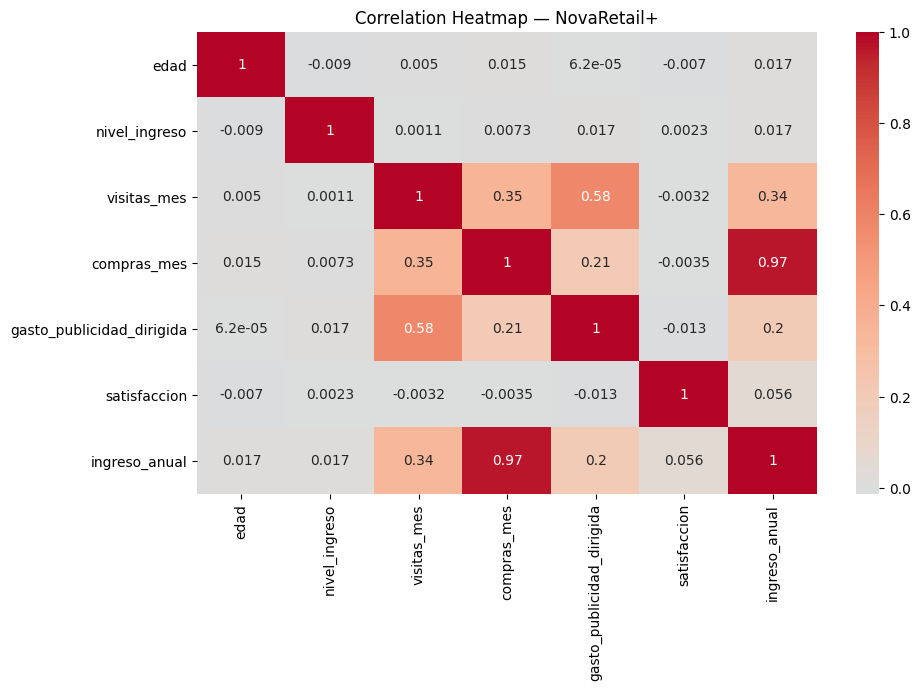

In [13]:
# Visualize the correlation matrix to identify relationships
variables_numericas = ['edad', 'nivel_ingreso', 'visitas_mes', 'compras_mes',
                        'gasto_publicidad_dirigida', 'satisfaccion', 'ingreso_anual']
corr = df[variables_numericas].corr()

plt.figure(figsize=(10,6))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap — NovaRetail+")
plt.show()

**General observations (heatmap)**
- The dominant correlation is `compras_mes` with `ingreso_anual` (0.97). The rest of the heatmap is comparatively weak, which makes this relationship stand out as the main finding of the analysis.
- There is a clear "commercial activity/value" cluster: `visitas_mes`, `compras_mes`, `gasto_publicidad_dirigida` and `ingreso_anual` are related to each other to a greater or lesser extent.
- `edad`, `nivel_ingreso` and `satisfaccion` behave as "isolated" variables: they are not linearly related to the commercial cluster or to each other.

**Observations regarding `ingreso_anual`**

`compras_mes` with `ingreso_anual` (0.97) is by far the strongest correlation in the whole heatmap: practically a near-perfect linear relationship. It makes sense: if `ingreso_anual` is the revenue a customer generates for the company, it is consistent for it to move almost in parallel with the number of purchases the customer makes. It should be reviewed whether one variable is derived from the other (that is, whether one was calculated from the other).

### General scatterplot

A general scatterplot is not included because the heatmap above shows that most of those relationships have a correlation close to 0 (`edad`, `nivel_ingreso` and `satisfaccion` are unrelated to almost everything). Plotting those combinations adds no new information and shows no pattern; moreover, with the number of records and variables involved, the plot tends to become visually saturated.

### Scatterplot for key pairs

The pairs with moderate or strong relationships with `ingreso_anual` are visualized.

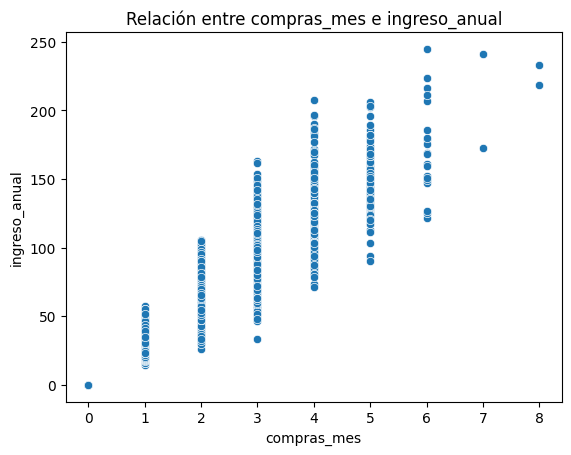

In [14]:
# Visualize pairs of variables with moderate or strong relationships
sns.scatterplot(
    data=df,
    x="compras_mes",
    y="ingreso_anual"
)

plt.title("Relación entre compras_mes e ingreso_anual")
plt.xlabel("compras_mes")
plt.ylabel("ingreso_anual")
plt.show()

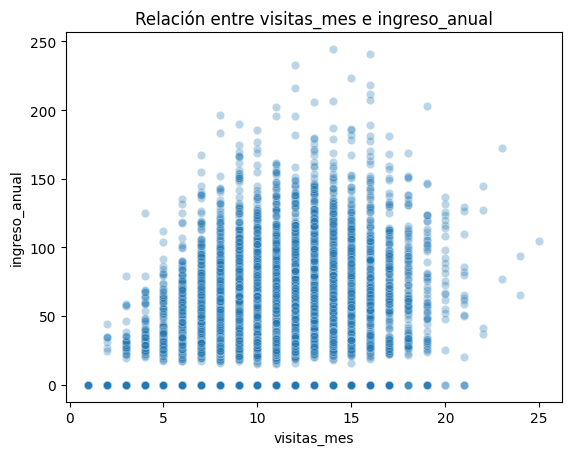

In [15]:

sns.scatterplot(data=df, x='visitas_mes', y='ingreso_anual', alpha=0.3)
plt.title('Relación entre visitas_mes e ingreso_anual')
plt.show()

Comparing the two scatterplots shows a clear contrast: `compras_mes` has a strong, orderly relationship with `ingreso_anual`, while `visitas_mes` shows a much weaker and more scattered relationship with the same variable. The direction is positive in both cases, but far more pronounced in the first. This suggests that the revenue a customer generates depends mainly on how much they buy, and not so much on how often they visit the platform: visiting does not guarantee buying.

**`compras_mes` vs `ingreso_anual`**
- **Direction:** positive and strong. The more purchases, the higher the annual revenue generated.
- **Dispersion:** moderate within each value of `compras_mes`, but the overall pattern clearly rises (a "staircase" shape).
- **Outliers:** mild, a few isolated points at high values of `compras_mes` (6–8), without breaking the trend.
- **Collinearity:** high. It visually confirms the 0.97 from the heatmap; both variables are probably measuring the same phenomenon from different angles (quantity vs. monetary value).

**`visitas_mes` vs `ingreso_anual`**
- **Direction:** positive but weak. A slight upward trend is visible up to ~15 visits; after that it flattens and even declines slightly toward the end.
- **Dispersion:** high. For the same number of visits (for example, 10–15), `ingreso_anual` ranges from 0 to over 200.
- **Outliers:** a band of points at `ingreso_anual` = 0 stands out across almost the whole range of visits: customers who visit but generate no revenue.
- **Collinearity:** low. It is consistent with the 0.34 correlation seen earlier: visiting does not guarantee generating revenue; the visit has to be converted into a purchase.

## Section 4. Correlation coefficients and numerical evidence

This section reports coefficients that support the patterns observed visually, using the appropriate method for each type of variable.

### Pearson / Spearman

The Pearson and Spearman coefficients are calculated between `ingreso_anual` and the two key pairs: `compras_mes` and `visitas_mes`.

In [16]:
# Calculate the correlation between relevant variables

corr_pearson  = df['compras_mes'].corr(df['ingreso_anual'], method='pearson')
corr_spearman  = df['compras_mes'].corr(df['ingreso_anual'], method='spearman')
print(f"Pearson: {corr_pearson:.3f}")
print(f"Spearman: {corr_spearman:.3f}")


Pearson: 0.967
Spearman: 0.967


In [17]:
# Calculate the correlation between relevant variables
corr_pearson_v2 = df['visitas_mes'].corr(df['ingreso_anual'], method='pearson')
corr_spearman_v2 = df['visitas_mes'].corr(df['ingreso_anual'], method='spearman')
print(f"Pearson: {corr_pearson_v2:.3f}")
print(f"Spearman: {corr_spearman_v2:.3f}")

Pearson: 0.337
Spearman: 0.321


**Correlation observations**

**`compras_mes` vs `ingreso_anual`**
- **Correlation:** Pearson 0.967 | Spearman 0.967.
- **Direction:** positive.
- **Magnitude:** very strong; it is only 0.033 away from a perfect correlation (1.0).
- **Possible collinearity:** high. The fact that Pearson and Spearman almost exactly coincide confirms that the relationship is not just monotonic, but practically linear.

**`visitas_mes` vs `ingreso_anual`**
- **Correlation:** Pearson 0.337 | Spearman 0.321.
- **Direction:** positive, but much weaker than the previous pair.
- **Magnitude:** weak-to-moderate; far from indicating a strong relationship.
- **Possible collinearity:** low. Pearson (0.337) and Spearman (0.321) are similar but not identical; the small difference suggests that the relationship, although weak, has somewhat more dispersion.

### Point-biserial

The point-biserial correlation is calculated between `ingreso_anual` and the binary variables `abandono` and `miembro_premium`.

In [18]:
# Calculate the correlation between relevant variables
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
from scipy.stats import pointbiserialr

pb_abandono, _ = pointbiserialr(df["abandono"], df["ingreso_anual"])
print("Correlación entre: abandono e ingreso_anual")
print(f"Punto-biserial: {pb_abandono:.3f}")

pb_premium, _ = pointbiserialr(df["miembro_premium"], df["ingreso_anual"])
print("Correlación entre: miembro_premium e ingreso_anual")
print(f"Punto-biserial: {pb_premium:.3f}")

Correlación entre: abandono e ingreso_anual
Punto-biserial: -0.003
Correlación entre: miembro_premium e ingreso_anual
Punto-biserial: 0.093


**Point-biserial observations**

**`abandono` vs `ingreso_anual`**
- **Point-biserial:** -0.003.
- **Direction:** negative, but practically nonexistent.
- **Magnitude:** extremely low, almost zero. A value this close to 0 means there is no detectable linear relationship between whether a customer leaves and the annual revenue they generate.

**`miembro_premium` vs `ingreso_anual`**
- **Point-biserial:** 0.093.
- **Direction:** positive.
- **Magnitude:** low. Although higher than the previous one, it is still a weak relationship: premium customers tend to generate very slightly more annual revenue, but the relationship is far from strong.

### Cramér's V

Cramér's V is calculated to measure the association between categorical variables: `region` with `tipo_dispositivo`, and `region` with `miembro_premium`.

In [19]:

# Function to calculate Cramér's V
import numpy as np
from scipy.stats import chi2_contingency

def cramer_v(df, col1, col2):
    tabla = pd.crosstab(df[col1], df[col2])
    chi2, p_value, dof, expected = chi2_contingency(tabla)
    n = tabla.values.sum()
    v = np.sqrt(chi2 / (n * (min(tabla.shape) -1)))
    return v

coef_cramer = cramer_v(df, "region", "tipo_dispositivo")

print("\nCorrelación entre: region y tipo dispositivo")
print(f"V de Cramér: {coef_cramer :.3f}")



Correlación entre: region y tipo dispositivo
V de Cramér: 0.012


In [20]:
# Apply Cramér's V to relevant variables
import numpy as np
from scipy.stats import chi2_contingency

def cramer_v(df, col1, col2):
    tabla = pd.crosstab(df[col1], df[col2])
    chi2, p_value, dof, expected = chi2_contingency(tabla)
    n = tabla.values.sum()
    v = np.sqrt(chi2 / (n * (min(tabla.shape) -1)))
    return v

coef_cramer = cramer_v(df, "region", "miembro_premium")

print("\nCorrelación entre: region y miembro premium")
print(f"V de Cramér: {coef_cramer :.3f}")



Correlación entre: region y miembro premium
V de Cramér: 0.013


**`region` vs `tipo_dispositivo`** (Cramér's V = 0.012)

The correlation between these two variables is practically zero. There is no relevant relationship between the region where the customer is located and the type of device they use: the use of mobile, tablet or desktop is distributed very similarly regardless of whether the customer is from the north, south, east or west. In practice, these two variables are independent of each other.

**`region` vs `miembro_premium`** (Cramér's V = 0.013)

The correlation between these two variables is practically zero. There is no relevant association between the customer's region and whether they have a premium membership. The proportion of premium customers is similar across all regions (north, south, east and west), with none standing out significantly.

## Section 5. Findings

### Finding 1. Purchases and annual revenue

**Visual evidence:** scatterplot and heatmap.
**Numerical evidence:** Pearson ≈ 0.967 | Spearman ≈ 0.967.

**Interpretation:** the number of monthly purchases is, by far, the factor most strongly associated with the annual revenue a customer generates. The relationship is almost perfectly linear, and it is confirmed both visually (an orderly upward pattern in the scatterplot) and numerically (Pearson and Spearman practically identical).

**What we cannot claim:** that making more purchases directly causes higher annual revenue. Both variables could be measuring essentially the same phenomenon from different angles (frequency vs. monetary value), rather than a causal relationship between two independent facts.

**Business implication:** if the goal is to increase the revenue generated per customer, the most direct lever is to increase purchase frequency. However, given that `compras_mes` and `ingreso_anual` show such a high correlation (0.97), both variables are probably capturing essentially the same phenomenon. For that reason, for predictive modeling it is recommended to use only one of the two as an explanatory variable, avoiding including both at once so as not to artificially inflate the apparent strength of the model.

### Finding 2. Visits and annual revenue

**Visual evidence:** scatterplot and heatmap.
**Numerical evidence:** Pearson ≈ 0.337 | Spearman ≈ 0.321.

**Interpretation:** monthly visits show a positive but weak relationship with annual revenue. A considerable band of customers visit the platform frequently but generate zero revenue, which indicates that a visit on its own does not translate into economic value for the company.

**What we cannot claim:** that increasing a customer's visits will increase the revenue they generate proportionally. The high dispersion observed in the scatterplot suggests that other factors (such as converting that visit into a purchase) are more decisive.

**Business implication:** instead of investing only in increasing traffic or visits, the Growth and Retention team should focus on improving the visit-to-purchase conversion rate, since that is the step that actually drives revenue (validated in Finding 1). Exploring why this group of customers visits without buying could reveal friction in the purchase process.

## Section 6. Limitations and next steps

### Limitations

- Correlation ≠ causation: all the reported coefficients (Pearson, Spearman, point-biserial and Cramér's V) describe association, not cause-and-effect relationships.
- The analysis is purely correlational/exploratory; external variables were not controlled and no controlled experiments (A/B testing) were run to isolate the real effect of each factor.
- Some variables show possible collinearity (`compras_mes` and `ingreso_anual`), which could artificially inflate the perception of the "most important factor" if they are used together in a future predictive model.
- The categorical variables analyzed (`region`, `tipo_dispositivo`) showed no relevant association with any other variable, which limits their usefulness for segmentation in this specific dataset.
- The association coefficients with binary variables (`abandono`, `miembro_premium`) were all low, which suggests that a simple linear approach does not capture these relationships well: there may be nonlinear patterns or interactions between variables that are not explored here.

### Next steps

**Test additional segmentation**
- Analyze whether the relationship between `visitas_mes` and `ingreso_anual` changes when segmenting by `tipo_dispositivo` or `miembro_premium`.
- Explore the specific group of customers with `ingreso_anual` = 0 to identify common patterns (age, region, satisfaction).

**Dig deeper into nonlinear relationships**
- Apply classification models (for example, logistic regression) to better understand what predicts churn, since the linear correlations were low.
- Explore interactions between variables (for example, `visitas_mes` × `gasto_publicidad_dirigida`) instead of analyzing them in isolation.

**Validate with controlled experiments**
- Design an A/B test that modulates visit frequency or pre-purchase engagement, to check whether there is a real causal relationship with the revenue generated, and not just association.